# Prepare PanopTILs Refined

Prepare image patches and matching nucleus and cell-type labels from
[PanopTILs Refined](https://huggingface.co/datasets/histolytics-hub/panoptils_refined)
for training. An instance label identifies one nucleus; a class label describes
its type. The dataset is CC0-1.0 and builds on PanopTILs, BCSS and NuCLS.

Download the data, separate patients into training and validation sets, then crop
images and labels together. Only nucleus instances and cell types are used here.


In [1]:
import hashlib
import json
import random
from pathlib import Path
from tempfile import TemporaryDirectory

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from huggingface_hub import hf_hub_download
from matplotlib.patches import Patch
from scipy.io import loadmat, savemat
from skimage.color import label2rgb
from skimage.measure import regionprops

dataset_id = "histolytics-hub/panoptils_refined"
revision = "d40293bc1ac0d0da8f271959fdb990aeea2d884f"
archive_sha256 = "1ab3f0c2299e0c44f996e34c233846592a934aa3dcfc8e80cc983db85c771d18"
patch_size = 256
seed = 42
data_root = Path("../../data/panoptils-nuclei")
class_names = [
    "background",
    "neoplastic",
    "stromal",
    "inflammatory",
    "epithelial",
    "other",
    "unknown",
]


## Download the dataset

Use the same dataset version throughout preparation, training and fine-tuning.


In [2]:
archive = Path(
    hf_hub_download(
        repo_id=dataset_id,
        repo_type="dataset",
        filename="panoptils_refined.parquet",
        revision=revision,
    )
)
checksum = hashlib.sha256()
with archive.open("rb") as source:
    for block in iter(lambda: source.read(8 * 1024 * 1024), b""):
        checksum.update(block)
if checksum.hexdigest() != archive_sha256:
    raise ValueError("The downloaded archive does not match the expected dataset")


## Split by patient

Keep each patient's images in one split so validation checks the model on new
patients. Use about 80% of patients for training and 20% for validation.


In [3]:
regions = pd.read_parquet(archive, columns=["slide_name"])
# Slides from one patient share the first three TCGA identifier fields.
regions["patient"] = regions["slide_name"].str.split("-").str[:3].str.join("-")
patients = sorted(regions["patient"].unique())
if len(patients) < 2:
    raise ValueError("Need at least two patients for separate splits")
random.Random(seed).shuffle(patients)
validation_patients = patients[: max(1, len(patients) // 5)]

regions["split"] = np.where(
    regions["patient"].isin(validation_patients), "validation", "train"
)
regions["file"] = regions.index.map(lambda i: f"region_{i:04d}")


## Read images and labels

Each region contains an RGB image, a nucleus-instance mask and a cell-type mask.
The masks must line up with the image. Zero in the instance mask is background;
positive numbers identify nuclei.


In [4]:
def decode_png(data: bytes) -> np.ndarray:
    # Keep the original integer precision of the label masks.
    return cv2.imdecode(np.frombuffer(data, dtype=np.uint8), cv2.IMREAD_UNCHANGED)


def decode_region(row: pd.Series) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    image = decode_png(row["image"])
    instances = decode_png(row["inst"])
    cell_types = decode_png(row["type"])
    if image.ndim != 3 or image.shape[2] != 3:
        raise ValueError("Expected a three-channel colour image")
    # OpenCV reads BGR; plots and model inputs use RGB.
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    if instances.shape != image.shape[:2] or cell_types.shape != instances.shape:
        raise ValueError("Image and masks must have matching dimensions")
    if cell_types.max() >= len(class_names) or cell_types[instances == 0].any():
        raise ValueError("Cell types must use IDs 0–6, with 0 on background")
    height, width = instances.shape
    if height % patch_size or width % patch_size:
        raise ValueError("Region dimensions must be multiples of patch_size")
    return image, instances, cell_types


## Count nuclei by cell type

Count each nucleus once in its original region, before cropping. This avoids
counting it again when it crosses a patch boundary. Its type is the most common
nonzero label inside its mask. A nucleus with no nonzero type label is “untyped”.


In [5]:
def count_nuclei(instances: np.ndarray, cell_types: np.ndarray) -> np.ndarray:
    counts = np.zeros(len(class_names), dtype=np.int64)
    for nucleus in regionprops(instances):
        # Inspect only this nucleus inside its bounding box.
        labels = cell_types[nucleus.slice][nucleus.image]
        votes = np.bincount(labels, minlength=len(class_names))
        votes[0] = 0  # Ignore background pixels when choosing the cell type.
        counts[votes.argmax()] += 1
    return counts


## Save matching images and masks

Save each image as a PNG and its two masks in a MAT file with the same name.
The MAT file keeps the nucleus IDs in `inst` and the cell types in `type`.


In [6]:
def save_sample(
    folder: Path,
    name: str,
    image: np.ndarray,
    instances: np.ndarray,
    cell_types: np.ndarray,
) -> None:
    image_path = folder / "images" / f"{name}.png"
    # Convert RGB back to OpenCV's BGR order before saving.
    if not cv2.imwrite(str(image_path), cv2.cvtColor(image, cv2.COLOR_RGB2BGR)):
        raise OSError(f"Could not write {image_path}")
    savemat(
        folder / "labels" / f"{name}.mat",
        {"inst": instances.astype(np.int32), "type": cell_types},
        do_compression=True,
    )


## Create the patches

Cut each 1024-pixel region into sixteen 256-pixel patches, cropping images and
masks together. Cropping keeps nuclei at their original size. Keep whole validation
images as well so you can inspect complete predictions later.

Choose a new `data_root` folder for preparation. Reuse it for training and fine-tuning.


In [7]:
if data_root.exists():
    raise FileExistsError(f"Choose a new data_root folder: {data_root}")
counts = {
    split: {"regions": 0, "patches": 0, "class_instances": [0] * len(class_names)}
    for split in ("train", "validation")
}
data_root.parent.mkdir(parents=True, exist_ok=True)


# Publish the prepared folder only after every region has been saved.
with TemporaryDirectory(dir=data_root.parent, prefix=".panoptils-") as temporary:
    root = Path(temporary)
    for folder in (root / "train", root / "validation", root / "validation/regions"):
        (folder / "images").mkdir(parents=True)
        (folder / "labels").mkdir()

    # Decode one region at a time instead of loading all images into memory.
    batches = pq.ParquetFile(archive).iter_batches(
        batch_size=1, columns=["image", "inst", "type"]
    )
    for row_index, batch in enumerate(batches):
        image, instances, cell_types = decode_region(batch.to_pandas().iloc[0])
        split = regions.loc[row_index, "split"]
        region_name = regions.loc[row_index, "file"]
        counts[split]["regions"] += 1
        counts[split]["class_instances"] = (
            np.array(counts[split]["class_instances"])
            + count_nuclei(instances, cell_types)
        ).tolist()

        if split == "validation":
            save_sample(
                root / "validation/regions", region_name, image, instances, cell_types
            )
        height, width = instances.shape
        for y in range(0, height, patch_size):
            for x in range(0, width, patch_size):
                area = np.s_[y : y + patch_size, x : x + patch_size]
                name = f"{region_name}_y{y:04d}_x{x:04d}"
                save_sample(
                    root / split, name, image[area], instances[area], cell_types[area]
                )
                counts[split]["patches"] += 1

    manifest = {
        "dataset": dataset_id,
        "revision": revision,
        "sha256": archive_sha256,
        "patch_size": patch_size,
        "seed": seed,
        "samples": regions.rename_axis("row")
        .reset_index()[["row", "patient", "split", "file"]]
        .to_dict(orient="records"),
        "splits": counts,
    }
    (root / "manifest.json").write_text(json.dumps(manifest, indent=2) + "\n")
    if data_root.exists():
        raise FileExistsError(data_root)
    root.rename(data_root)

for split, count in counts.items():
    print(f"{split}: {count['regions']} regions, {count['patches']} patches")


train: 1096 regions, 17536 patches
validation: 253 regions, 4048 patches


## Inspect the nuclei and labels

The table counts nuclei, not pixels or cropped fragments. Neoplastic means tumour
cells; inflammatory means immune cells. Stromal cells support the surrounding
tissue, and epithelial cells form tissue linings. “Other” and “unknown” are labels
provided by the dataset. “Untyped” means a nucleus has no nonzero cell-type label.

Compare the image with its nucleus and cell-type labels.


In [8]:
manifest = json.loads((data_root / "manifest.json").read_text())
instance_counts = pd.DataFrame(
    {split: count["class_instances"] for split, count in manifest["splits"].items()},
    index=["untyped (class 0)", *class_names[1:]],
)
instance_counts.index.name = "Cell type"
instance_counts.columns.name = "Nuclei"
instance_counts


Nuclei,train,validation
Cell type,,
untyped (class 0),4392,935
neoplastic,233199,45557
stromal,167019,32384
inflammatory,145961,19144
epithelial,1148,90
other,3727,493
unknown,24433,7709


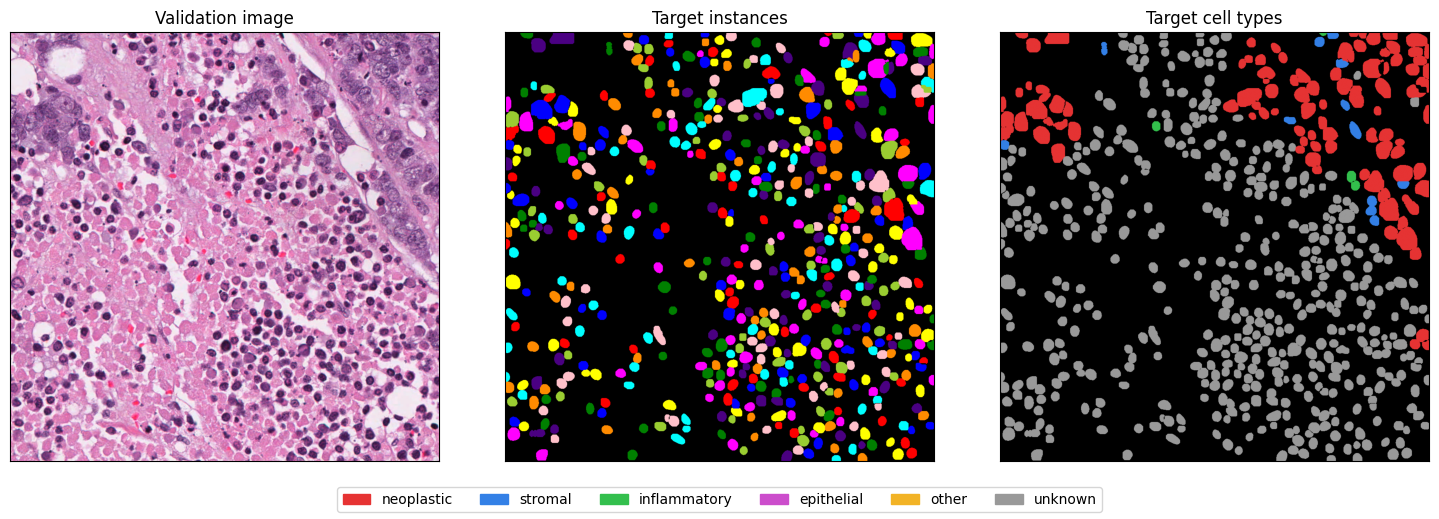

In [9]:
image_path = sorted((data_root / "validation/regions/images").glob("*.png"))[0]
image = cv2.cvtColor(cv2.imread(str(image_path)), cv2.COLOR_BGR2RGB)
labels = loadmat(data_root / "validation/regions/labels" / f"{image_path.stem}.mat")
class_palette = np.array(
    [
        [0, 0, 0],
        [0.9, 0.2, 0.2],
        [0.2, 0.5, 0.9],
        [0.2, 0.75, 0.3],
        [0.8, 0.3, 0.8],
        [0.95, 0.7, 0.15],
        [0.6, 0.6, 0.6],
    ]
)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(image)
axes[0].set_title("Validation image")
axes[1].imshow(label2rgb(labels["inst"], bg_label=0))
axes[1].set_title("Target instances")
axes[2].imshow(class_palette[labels["type"].astype(int)])
axes[2].set_title("Target cell types")
for axis in axes:
    axis.set(xticks=[], yticks=[])
fig.legend(
    [Patch(color=colour) for colour in class_palette[1:]],
    class_names[1:],
    loc="lower center",
    ncol=6,
)
fig.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()


Continue with [training](training.ipynb) or [fine-tuning](finetuning.ipynb).
